# Prepare Dataset, Function Definition, and Data Processing

In [ ]:
!pip install spectral
!mkdir dataset
! wget -P dataset https://download.scidb.cn/download?fileId=6374480bbae2f1393c11285b&path=/V6/data.7z&fileName=data.7z
%cd dataset
!7z x download?fileId=6374480bbae2f1393c11285b
%cd ..

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 249.0/249.0 kB 12.9 MB/s eta 0:00:00
--2025-11-30 07:57:58--  https://download.scidb.cn/download?fileId=6374480bbae2f1393c11285b
Resolving download.scidb.cn (download.scidb.cn)... 60.245.194.35
Connecting to download.scidb.cn (download.scidb.cn)|60.245.194.35|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1017930890 (971M) [application/octet-stream]
Saving to: ‘dataset/download?fileId=6374480bbae2f1393c11285b’

download?fileId=637 100%[===================>] 970.77M  11.6MB/s    in 89s     

2025-11-30 07:59:28 (10.9 MB/s) - ‘dataset/download?fileId=6374480bbae2f1393c11285b’ saved [1017930890/1017930890]

/content/dataset

7-Zip [64] 16.02 : Copyright (c) 1999-2016 Igor Pavlov : 2016-05-21
p7zip Version 16.02 (locale=en_US.UTF-8,Utf16=on,HugeFiles=on,64 bits,8 CPUs Intel(R) Xeon(R) CPU @ 2.00GHz (50653),ASM,AES-NI)

Scanning the drive for archives:
  0M Scan         1 file, 1017930890 bytes (971 MiB

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.metrics import classification_report, cohen_kappa_score, accuracy_score
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense, Dropout, Convolution2DTranspose
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.utils import to_categorical
from skimage.filters import gabor
import gc # Import the garbage collection module
from scipy.spatial.distance import pdist, squareform
from scipy.linalg import eigh
import gc # Import the garbage collection module
from matplotlib.colors import ListedColormap, BoundaryNorm

import os
import glob
import re


In [ ]:
def stack_image_patches(base_dir="/root/uav-hsi-dataset", data='XJM'):
    all_files = glob.glob(f"{base_dir}/**/rs/*.npy", recursive=True)

    if data in ['XJM', 'MJK_N', 'MJK_S']:
        ls = [path for path in all_files if data in path]
    else:
        raise ValueError("Invalid 'data' parameter. Choose from 'XJM', 'MJK_N', 'MJK_S'.")

    if not ls:
        return None, None, [], None

    expr = r"_(\d+)_(\d+)_(\d+)\.npy$"
    rcs_map = {}
    for path in ls:
        match = re.search(expr, path)
        if match:
            _, r, c = map(int, match.groups())
            if r not in rcs_map:
                rcs_map[r] = []
            rcs_map[r].append([c, path])

    rcs_map = {k: sorted(v, key=lambda x: x[0]) for k, v in rcs_map.items()}
    rcs_map = dict(sorted(rcs_map.items()))

    img_whole = None
    gt_whole = None
    file_order = []
    patch_shape = None

    for r_idx, (r, patches) in enumerate(rcs_map.items()):
        row_hstack = []
        gt_hstack = []
        for c, path in patches:
            arr = np.load(path)
            arr_gt = np.load(path.replace("rs", "gt"))

            if patch_shape is None:
                patch_shape = arr.shape

            row_hstack.append(arr)
            gt_hstack.append(arr_gt)
            file_order.append(path)

        row_patch = np.hstack(row_hstack)
        row_patch_gt = np.hstack(gt_hstack)

        img_whole = row_patch if img_whole is None else np.vstack([img_whole, row_patch])
        gt_whole = row_patch_gt if gt_whole is None else np.vstack([gt_whole, row_patch_gt])

    return img_whole, gt_whole, file_order, patch_shape

def unstack_image_to_patches(stacked_img, file_order, patch_shape, base_input_dir, base_output_dir):
    if stacked_img is None or not file_order or patch_shape is None:
        return

    p_h, p_w, _ = patch_shape
    try:
        img_h, img_w, _ = stacked_img.shape
    except:
        img_h, img_w = stacked_img.shape
    num_rows = img_h // p_h
    num_cols = img_w // p_w

    if len(file_order) != num_rows * num_cols:
        raise ValueError(f"Mismatch between number of files ({len(file_order)}) and "
                         f"calculated patches ({num_rows * num_cols}). Check patch_shape.")


    file_idx = 0
    for r in range(num_rows):
        for c in range(num_cols):
            start_row, end_row = r * p_h, (r + 1) * p_h
            start_col, end_col = c * p_w, (c + 1) * p_w

            try:
                patch = stacked_img[start_row:end_row, start_col:end_col, :]
            except:
                patch = stacked_img[start_row:end_row, start_col:end_col]

            original_full_path = file_order[file_idx]
            relative_path = os.path.relpath(original_full_path, start=base_input_dir)
            output_full_path = os.path.join(base_output_dir, relative_path)

            output_patch_dir = os.path.dirname(output_full_path)
            os.makedirs(output_patch_dir, exist_ok=True)

            np.save(output_full_path, patch)
            file_idx += 1



In [ ]:
# essential
import numpy as np
import gc
from scipy import sparse
from scipy.linalg import eigh
from sklearn.neighbors import NearestNeighbors

def lsp_prep_optimized(img, gt, N_COMPONENTS=3):

    h, w, b = img.shape
    gt_flat = gt.reshape(-1).astype(int)
    valid_indices = np.where(gt_flat != 0)[0]

    X_train = img.reshape(-1, b)[valid_indices].astype(np.float32)
    y_train = gt_flat[valid_indices]

    W_lsp = apply_lsp_sparse(X_train, y_train, N_COMPONENTS)

    del X_train, y_train, valid_indices, gt_flat
    gc.collect()

    flattened_img = img.reshape(-1, b)
    lsp_features = np.zeros((h * w, N_COMPONENTS), dtype=np.float32)

    chunk_size = 50000
    for i in range(0, h * w, chunk_size):
        end = min(i + chunk_size, h * w)
        lsp_features[i:end] = flattened_img[i:end].dot(W_lsp)

    lsp_image = lsp_features.reshape(h, w, N_COMPONENTS)

    del flattened_img, lsp_features
    gc.collect()

    gabor_image_features = create_gabor_features(lsp_image)

    fused_features = np.concatenate((lsp_image, gabor_image_features), axis=2)

    return fused_features

def apply_lsp_sparse(X, y, n_components, k_neighbors=7):
    n_samples, n_features = X.shape
    nbrs = NearestNeighbors(n_neighbors=k_neighbors+1, metric='euclidean', n_jobs=-1).fit(X)
    distances, indices = nbrs.kneighbors(X)

    sigmas = distances[:, k_neighbors]

    row_ind = np.repeat(np.arange(n_samples), k_neighbors)
    col_ind = indices[:, 1:].flatten()

    dist_sq = distances[:, 1:].flatten() ** 2
    sigma_vals = sigmas[row_ind] ** 2

    weights = np.exp(-dist_sq / (sigma_vals + 1e-8))

    A = sparse.csr_matrix((weights, (row_ind, col_ind)), shape=(n_samples, n_samples))
    A = (A + A.T) / 2

    rows, cols = A.nonzero()
    vals = A.data
    is_same_class = (y[rows] == y[cols])
    W_lw = sparse.csr_matrix((vals * is_same_class, (rows, cols)), shape=A.shape)
    W_lb = A - W_lw

    def compute_scatter(W_sparse):
        D_vec = np.array(W_sparse.sum(axis=1)).flatten()
        S1 = (X.T * D_vec) @ X
        WX = W_sparse.dot(X)
        S2 = X.T @ WX

        return S1 - S2

    S_lw = compute_scatter(W_lw)
    S_lb = compute_scatter(W_lb)

    del A, W_lw, W_lb, rows, cols, vals, is_same_class
    gc.collect()

    print("Solving eigenproblem")
    epsilon = 1e-6
    S_lw_reg = S_lw + epsilon * np.eye(n_features)


    eigenvalues, eigenvectors = eigh(S_lb, S_lw_reg)

    sorted_indices = np.argsort(eigenvalues)[::-1]
    W_lsp = eigenvectors[:, sorted_indices[:n_components]]

    return W_lsp

def apply_pca(im, n_components=3):
    h,w,c = im.shape
    res_im = im.reshape(-1, c)

    pca = PCA(n_components=n_components)
    tr_im = pca.fit_transform(res_im)
    pca_im = tr_im.reshape(h, w, n_components)

    return pca_im

def create_gabor_features(image):
    gabor_features = []
    num_components = image.shape[2]

    thetas = [0, np.pi/4, np.pi/2, 3*np.pi/4]
    freqs = [0.1, 0.2, 0.3]

    for i in range(num_components):
        component_image = image[:, :, i]
        for theta in thetas:
            for freq in freqs:
                real_response, _ = gabor(component_image, frequency=freq, theta=theta)
                gabor_features.append(real_response[:, :, np.newaxis])
    return np.concatenate(gabor_features, axis=2).astype(np.float32)

def pca_prep(img, gt, N_COMPONENTS=3):
    pca_image = apply_pca(img, N_COMPONENTS)
    del img; gc.collect()
    gabor_image_features = create_gabor_features(pca_image)
    fused_features = np.concatenate((pca_image, gabor_image_features), axis=2)
    return fused_features



In [ ]:
base_dir = "/content/dataset"

def preprocess(data, prep_func, output_dir, is_guided, N_COMPONENTS=3):
    img, gt, files, p_shape = stack_image_patches(base_dir=base_dir, data=data)


    if is_guided:
      pca_im = apply_pca(img)
      img = CostFPre(img, pca_im, 7, 0.00001)
    else:
      img = prep_func(img, gt, N_COMPONENTS)

    if img is not None:
        unstack_image_to_patches(
            stacked_img=img,
            file_order=files,
            patch_shape=p_shape,
            base_input_dir=base_dir,
            base_output_dir=output_dir
        )

        gt_file_order = [path.replace("/rs/", "/gt/") for path in files]

        unstack_image_to_patches(
            stacked_img=gt,
            file_order=gt_file_order,
            patch_shape=p_shape,
            base_input_dir=base_dir,
            base_output_dir=output_dir
        )

In [ ]:
output_dir = "/content/reverted"
preprocess('XJM', pca_prep, output_dir, False, 3) # 7 minutes
preprocess('MJK_N', pca_prep, output_dir, False, 3)
preprocess('MJK_S', pca_prep, output_dir, False, 3)

In [ ]:
output_dir = "/content/reverted_lsp"
preprocess('XJM', lsp_prep_optimized, output_dir, False, 3) # 7 minutes
preprocess('MJK_N', lsp_prep_optimized, output_dir, False, 3)
preprocess('MJK_S', lsp_prep_optimized, output_dir, False, 3)

In [ ]:
import glob

def load_and_stack(paths):
    if not paths:
        return None
    arrays = [np.load(p) for p in paths]
    return np.stack(arrays)

def load_dataset_impl(base_dir):
    tr_rs_path = sorted(glob.glob(os.path.join(base_dir, 'Train/Training/rs/*.npy')))
    tr_gt_path = sorted(glob.glob(os.path.join(base_dir, 'Train/Training/gt/*.npy')))
    val_rs_path = sorted(glob.glob(os.path.join(base_dir, 'Train/Validation/rs/*.npy')))
    val_gt_path = sorted(glob.glob(os.path.join(base_dir, 'Train/Validation/gt/*.npy')))
    ts_rs_path = sorted(glob.glob(os.path.join(base_dir, 'Test/rs/*.npy')))
    ts_gt_path = sorted(glob.glob(os.path.join(base_dir, 'Test/gt/*.npy')))

    tr_rs = load_and_stack(tr_rs_path)
    tr_gt = load_and_stack(tr_gt_path)
    val_rs = load_and_stack(val_rs_path)
    val_gt = load_and_stack(val_gt_path)
    ts_rs = load_and_stack(ts_rs_path)
    ts_gt = load_and_stack(ts_gt_path)

    return tr_rs, tr_gt, val_rs, val_gt, ts_rs, ts_gt

In [ ]:
def reindex_label(gt):
    class_labels = np.unique(gt)
    class_labels = class_labels[class_labels != 0]
    num_classes = len(class_labels)

    print(f"Found {num_classes} classes. Original labels: {class_labels}")
    label_map = {original: sequential for sequential, original in enumerate(class_labels)}

    gt_mapped = np.zeros_like(gt)
    for original, sequential in label_map.items():
        gt_mapped[gt == original] = sequential

    labeled_indices = np.where(gt > 0)
    coords = np.array(list(zip(labeled_indices[0], labeled_indices[1])))

    return gt_mapped

# Training


In [ ]:
import tensorflow as tf
from tensorflow.keras.layers import (
    Input, Conv2D, MaxPooling2D, BatchNormalization, Conv2DTranspose,
    concatenate, Activation, Dropout, SpatialDropout2D, UpSampling2D, Average, Add
)
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import (
    ReduceLROnPlateau, EarlyStopping, ModelCheckpoint
)
import numpy as np
import os
import gc
import time
from sklearn.metrics import accuracy_score, cohen_kappa_score

def make_dataset(X_spatial, X_spectral, y, batch_size, num_classes, shuffle=True):
    X_spatial = X_spatial.astype('float32')
    X_spectral = X_spectral.astype('float32')

    ds = tf.data.Dataset.from_tensor_slices(((X_spatial, X_spectral), y))

    if shuffle:
        ds = ds.shuffle(buffer_size=len(y))

    def process_step(x, y):
        inputs = {'spatial_input': x[0], 'spectral_input': x[1]}
        label = tf.cast(y, tf.float32)
        return inputs, label

    ds = ds.map(process_step, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)
    return ds


def compute_AA(y_true, y_pred, num_classes):
    aa_list = []
    for c in range(num_classes):
        mask = (y_true == c)
        if mask.sum() == 0:
            continue
        aa_list.append(np.mean(y_pred[mask] == c))
    return np.mean(aa_list)

def build_dcnn_model(spatial_input_shape, spectral_input_shape, num_classes,
                     ablation_mode='fusion', l2_reg=1e-4):
    inputs_list = []

    spatial_input = Input(shape=spatial_input_shape, name='spatial_input')
    spectral_input = Input(shape=spectral_input_shape, name='spectral_input')


    if ablation_mode == 'spatial':
        fused_features = spatial_input
        inputs_list = [spatial_input]
        print(f"[{ablation_mode.upper()}] Building Spatial-Only Model...")

    elif ablation_mode == 'spectral':
        inputs_list = [spectral_input]
        print(f"[{ablation_mode.upper()}] Building Spectral-Only Model...")
        spec_tunnel = Conv2D(32, (1, 1), activation='relu', padding='same', kernel_regularizer=l2(l2_reg))(spectral_input)
        spec_tunnel = BatchNormalization()(spec_tunnel)
        spec_tunnel = Conv2D(64, (1, 1), activation='relu', padding='same', kernel_regularizer=l2(l2_reg))(spec_tunnel)

        fused_features = spec_tunnel

    elif ablation_mode == 'fusion':
        inputs_list = [spatial_input, spectral_input]
        print(f"[{ablation_mode.upper()}] Building Spatial-Spectral Fusion Model...")
        spec_tunnel = Conv2D(32, (1, 1), activation='relu', padding='same', kernel_regularizer=l2(l2_reg))(spectral_input)
        spec_tunnel = BatchNormalization()(spec_tunnel)
        spec_tunnel = Conv2D(64, (1, 1), activation='relu', padding='same', kernel_regularizer=l2(l2_reg))(spec_tunnel)

        fused_features = concatenate([spec_tunnel, spatial_input])

    else:
        raise ValueError("Invalid ablation_mode. Choose: 'spatial', 'spectral', 'fusion'")

    c1 = Conv2D(50, (5, 5), activation='relu', padding='same', kernel_regularizer=l2(l2_reg))(fused_features)
    s1 = MaxPooling2D((2, 2))(c1)

    c2 = Conv2D(50, (5, 5), activation='relu', padding='same', kernel_regularizer=l2(l2_reg))(s1)
    s2 = MaxPooling2D((2, 2))(c2)

    u_c2 = Conv2DTranspose(50, (3, 3), strides=2, padding='same', activation='relu', kernel_regularizer=l2(l2_reg))(s2)
    u_c2 = BatchNormalization()(u_c2)

    dcnn_output = Conv2DTranspose(50, (3, 3), strides=2, padding='same', activation='relu', kernel_regularizer=l2(l2_reg))(u_c2)

    classifier_1_logits = Conv2D(
        num_classes, (1, 1),
        padding='same',
        kernel_regularizer=l2(l2_reg),
        name='classifier_1_logits'
    )(dcnn_output)
    classifier_1 = Activation('softmax', name='classifier_1')(classifier_1_logits)

    refinement = Conv2D(
        50, (3, 3),
        activation='swish',
        padding='same',
        kernel_regularizer=l2(l2_reg),
        name='refinement_conv'
    )(dcnn_output)
    refinement = BatchNormalization(name='refinement_bn')(refinement)
    refinement = SpatialDropout2D(0.1, name='refinement_dropout')(refinement)

    classifier_2_logits = Conv2D(
        num_classes, (1, 1),
        padding='same',
        kernel_regularizer=l2(l2_reg),
        name='classifier_2_logits'
    )(refinement)
    classifier_2 = Activation('softmax', name='classifier_2')(classifier_2_logits)

    outputs = Average(name='final_output')([classifier_1, classifier_2])

    model = Model(inputs=inputs_list, outputs=outputs)
    optimizer = Adam(learning_rate=1e-3)

    model.compile(optimizer=optimizer,
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])

    return model

def run_ablation_study(load_dataset_func, output_dir, base_dir, save_dir, num_classes,
                       BATCH_SIZE=32, EPOCHS=300, runs=3):

    tr_rs_spat, tr_gt, val_rs_spat, val_gt, ts_rs_spat, ts_gt = load_dataset_func(output_dir)
    tr_rs_spec, _,      val_rs_spec, _,      ts_rs_spec, _      = load_dataset_func(base_dir)

    train_ds = make_dataset(tr_rs_spat, tr_rs_spec, tr_gt, BATCH_SIZE, num_classes, shuffle=True)
    val_ds   = make_dataset(val_rs_spat, val_rs_spec, val_gt, BATCH_SIZE, num_classes, shuffle=False)
    test_ds  = make_dataset(ts_rs_spat, ts_rs_spec, ts_gt, BATCH_SIZE, num_classes, shuffle=False)

    spatial_shape = tr_rs_spat.shape[1:]
    spectral_shape = tr_rs_spec.shape[1:]

    ablation_results = {}

    modes = ['spectral', 'fusion', 'spatial']

    os.makedirs(save_dir, exist_ok=True)

    for mode in modes:
        print("\n" + "#"*60)
        print(f"🧪 STARTING ABLATION MODE: {mode.upper()}")
        print("#"*60)

        oa_list, aa_list, kappa_list, time_list = [], [], [], []

        for r in range(runs):
            print(f"\n--- Run {r+1}/{runs} [{mode}] ---")

            tf.keras.backend.clear_session()
            gc.collect()

            model = build_dcnn_model(
                spatial_shape, spectral_shape, num_classes,
                ablation_mode=mode
            )

            model_filename = os.path.join(save_dir, f"best_model_{mode}_run_{r+1}.keras")

            callbacks = [
                ReduceLROnPlateau(monitor='val_loss', factor=0.8, patience=15, verbose=1),
                EarlyStopping(monitor='val_loss', patience=100, restore_best_weights=True),

                ModelCheckpoint(model_filename, monitor='val_loss', save_best_only=True, verbose=0)
            ]

            start_time = time.time()
            model.fit(
                train_ds,
                validation_data=val_ds,
                epochs=EPOCHS,
                callbacks=callbacks,
                verbose=1
            )
            end_time = time.time()
            duration = end_time - start_time

            print(f"Evaluating {mode} run {r+1}...")
            y_pred_probs = model.predict(test_ds)
            y_pred = np.argmax(y_pred_probs, axis=-1)

            yt = ts_gt.flatten()
            yp = y_pred.flatten()

            oa = accuracy_score(yt, yp)
            kappa = cohen_kappa_score(yt, yp)
            aa = compute_AA(yt, yp, num_classes)

            print(f"Result [{mode} Run {r+1}]: OA={oa:.4f}, AA={aa:.4f}, Kappa={kappa:.4f}, Time={duration:.2f}s")

            oa_list.append(oa)
            aa_list.append(aa)
            kappa_list.append(kappa)
            time_list.append(duration)

        ablation_results[mode] = {
            "OA_mean": np.mean(oa_list), "OA_std": np.std(oa_list),
            "AA_mean": np.mean(aa_list), "AA_std": np.std(aa_list),
            "Kappa_mean": np.mean(kappa_list), "Kappa_std": np.std(kappa_list),
            "Time_mean": np.mean(time_list)
        }

    print("\n" + "="*80)
    print("📊 ABLATION STUDY FINAL REPORT")
    print("="*80)
    print(f"{'MODE':<15} | {'OA (Mean ± Std)':<20} | {'AA (Mean ± Std)':<20} | {'Kappa (Mean ± Std)':<20} | {'Time (s)':<10}")
    print("-" * 100)

    for mode in modes:
        res = ablation_results[mode]
        print(f"{mode.upper():<15} | "
              f"{res['OA_mean']:.4f} ± {res['OA_std']:.4f}   | "
              f"{res['AA_mean']:.4f} ± {res['AA_std']:.4f}   | "
              f"{res['Kappa_mean']:.4f} ± {res['Kappa_std']:.4f}   | "
              f"{res['Time_mean']:.1f}")

    return ablation_results

In [ ]:
# PCA
output_dir = "/content/reverted"
base_dir = "/content/dataset"
save_dir = "ablation_checkpoints_pca"
num_classes = 30
EPOCHS = 300

run_ablation_study(load_dataset_impl, output_dir, base_dir, save_dir, num_classes=num_classes, EPOCHS=EPOCHS)

Loading datasets...

############################################################
🧪 STARTING ABLATION MODE: SPECTRAL
############################################################

--- Run 1/3 [spectral] ---
[SPECTRAL] Building Spectral-Only Model...
Epoch 1/300
10/10 ━━━━━━━━━━━━━━━━━━━━ 19s 1s/step - accuracy: 0.2366 - loss: 3.1130 - val_accuracy: 0.1630 - val_loss: 3.4116 - learning_rate: 0.0010
Epoch 2/300
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 185ms/step - accuracy: 0.5726 - loss: 2.1125 - val_accuracy: 0.3985 - val_loss: 3.3249 - learning_rate: 0.0010
Epoch 3/300
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 178ms/step - accuracy: 0.6282 - loss: 1.8084 - val_accuracy: 0.4044 - val_loss: 3.2859 - learning_rate: 0.0010
Epoch 4/300
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 184ms/step - accuracy: 0.6280 - loss: 1.6932 - val_accuracy: 0.4100 - val_loss: 3.1952 - learning_rate: 0.0010
Epoch 5/300
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 177ms/step - accuracy: 0.6634 - loss: 1.5375 - val_accuracy: 0.3043 - val_loss: 3.1699 - learning_r

2/3 ━━━━━━━━━━━━━━━━━━━━ 0s 151ms/step

3/3 ━━━━━━━━━━━━━━━━━━━━ 3s 559ms/step
Result [spectral Run 1]: OA=0.8872, AA=0.4914, Kappa=0.8666

--- Run 2/3 [spectral] ---
[SPECTRAL] Building Spectral-Only Model...
Epoch 1/300
10/10 ━━━━━━━━━━━━━━━━━━━━ 18s 1s/step - accuracy: 0.1656 - loss: 3.2640 - val_accuracy: 0.2389 - val_loss: 3.4105 - learning_rate: 0.0010
Epoch 2/300
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 189ms/step - accuracy: 0.5312 - loss: 2.1876 - val_accuracy: 0.4351 - val_loss: 3.3635 - learning_rate: 0.0010
Epoch 3/300
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 186ms/step - accuracy: 0.6082 - loss: 1.8316 - val_accuracy: 0.4327 - val_loss: 3.2740 - learning_rate: 0.0010
Epoch 4/300
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 185ms/step - accuracy: 0.6542 - loss: 1.6559 - val_accuracy: 0.4647 - val_loss: 3.1762 - learning_rate: 0.0010
Epoch 5/300
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 186ms/step - accuracy: 0.6725 - loss: 1.5076 - val_accuracy: 0.4535 - val_loss: 3.0852 - learning_rate: 0.0010
Epoch 6/300
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 186ms/step - accuracy: 0.

{'spectral': {'OA_mean': np.float64(0.8837973772083866),
  'OA_std': np.float64(0.0026665400725418295),
  'AA_mean': np.float64(0.47359993280462614),
  'AA_std': np.float64(0.017435365204358937),
  'Kappa_mean': np.float64(0.862432510017408),
  'Kappa_std': np.float64(0.0033177926453180724)},
 'fusion': {'OA_mean': np.float64(0.8800320615155385),
  'OA_std': np.float64(0.0032585017023879573),
  'AA_mean': np.float64(0.49183118538172654),
  'AA_std': np.float64(0.002009728255318012),
  'Kappa_mean': np.float64(0.8582385868391073),
  'Kappa_std': np.float64(0.003643369059532122)},
 'spatial': {'OA_mean': np.float64(0.8386335441943381),
  'OA_std': np.float64(0.0019386374264710475),
  'AA_mean': np.float64(0.3977887516440863),
  'AA_std': np.float64(0.0005589703073873855),
  'Kappa_mean': np.float64(0.8075848173258882),
  'Kappa_std': np.float64(0.002372360845887549)}}

In [ ]:
# LSP
output_dir = "/content/reverted_lsp"
base_dir = "/content/dataset"
save_dir = "ablation_checkpoints"
num_classes = 30
EPOCHS = 300

run_ablation_study(load_dataset_impl, output_dir, base_dir,save_dir, num_classes=num_classes, EPOCHS=EPOCHS)

Loading datasets...

############################################################
🧪 STARTING ABLATION MODE: SPECTRAL
############################################################

--- Run 1/3 [spectral] ---
[SPECTRAL] Building Spectral-Only Model...
Epoch 1/300
10/10 ━━━━━━━━━━━━━━━━━━━━ 35s 2s/step - accuracy: 0.1786 - loss: 3.2042 - val_accuracy: 0.4176 - val_loss: 3.3926 - learning_rate: 0.0010
Epoch 2/300
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 174ms/step - accuracy: 0.5811 - loss: 2.0623 - val_accuracy: 0.3451 - val_loss: 3.3342 - learning_rate: 0.0010
Epoch 3/300
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 176ms/step - accuracy: 0.6254 - loss: 1.7758 - val_accuracy: 0.4225 - val_loss: 3.2332 - learning_rate: 0.0010
Epoch 4/300
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 181ms/step - accuracy: 0.6368 - loss: 1.6844 - val_accuracy: 0.3059 - val_loss: 3.1856 - learning_rate: 0.0010
Epoch 5/300
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 185ms/step - accuracy: 0.6785 - loss: 1.5175 - val_accuracy: 0.3059 - val_loss: 3.0809 - learning_r

2/3 ━━━━━━━━━━━━━━━━━━━━ 0s 141ms/step

3/3 ━━━━━━━━━━━━━━━━━━━━ 2s 549ms/step
Result [spectral Run 3]: OA=0.8798, AA=0.4822, Kappa=0.8575, Time=529.40s

############################################################
🧪 STARTING ABLATION MODE: FUSION
############################################################

--- Run 1/3 [fusion] ---
[FUSION] Building Spatial-Spectral Fusion Model...
Epoch 1/300
10/10 ━━━━━━━━━━━━━━━━━━━━ 29s 2s/step - accuracy: 0.2037 - loss: 3.1903 - val_accuracy: 0.1827 - val_loss: 3.4068 - learning_rate: 0.0010
Epoch 2/300
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 190ms/step - accuracy: 0.5437 - loss: 2.1917 - val_accuracy: 0.3522 - val_loss: 3.3587 - learning_rate: 0.0010
Epoch 3/300
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 189ms/step - accuracy: 0.6246 - loss: 1.8499 - val_accuracy: 0.3044 - val_loss: 3.3109 - learning_rate: 0.0010
Epoch 4/300
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 189ms/step - accuracy: 0.6450 - loss: 1.6969 - val_accuracy: 0.3043 - val_loss: 3.2627 - learning_rate: 0.0010
Epoch 5/300
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 19

{'spectral': {'OA_mean': np.float64(0.8844592279959557),
  'OA_std': np.float64(0.003881151084230437),
  'AA_mean': np.float64(0.48972288274645953),
  'AA_std': np.float64(0.006355663966762774),
  'Kappa_mean': np.float64(0.8632247037351681),
  'Kappa_std': np.float64(0.0049419181610921405),
  'Time_mean': np.float64(504.14384365081787)},
 'fusion': {'OA_mean': np.float64(0.8748528296615582),
  'OA_std': np.float64(0.001225561926668554),
  'AA_mean': np.float64(0.4702493858328345),
  'AA_std': np.float64(0.014196896987853987),
  'Kappa_mean': np.float64(0.8517297791241255),
  'Kappa_std': np.float64(0.0016074565277525116),
  'Time_mean': np.float64(506.61291726430255)},
 'spatial': {'OA_mean': np.float64(0.8157140505268199),
  'OA_std': np.float64(0.0013898291869103724),
  'AA_mean': np.float64(0.36312465658008614),
  'AA_std': np.float64(0.00744341280241547),
  'Kappa_mean': np.float64(0.7797388967777317),
  'Kappa_std': np.float64(0.0020266955689695557),
  'Time_mean': np.float64(473

# Visualization

🚀 Starting Automatic Prediction Pipeline...

Processing Mode: SPECTRAL
  Loading model: best_model_spectral_run_2.keras
    Predicting on XJM...
    Predicting on MJK_N...
    Predicting on MJK_S...

Processing Mode: SPATIAL_LSP
  Loading model: best_model_spatial_run_2.keras
    Predicting on XJM...
    Predicting on MJK_N...
    Predicting on MJK_S...

Processing Mode: SPATIAL_PCA
  Loading model: best_model_spatial_run_3.keras
    Predicting on XJM...
    Predicting on MJK_N...
    Predicting on MJK_S...

Processing Mode: FUSION_LSP
  Loading model: best_model_fusion_run_3.keras
    Predicting on XJM...
    Predicting on MJK_N...
    Predicting on MJK_S...

Processing Mode: FUSION_PCA
  Loading model: best_model_fusion_run_1.keras
    Predicting on XJM...
    Predicting on MJK_N...
    Predicting on MJK_S...

Genering Transposed Plot...
Saving visualization to ablation_transposed.png...


/tmp/ipython-input-1982056244.py:249: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


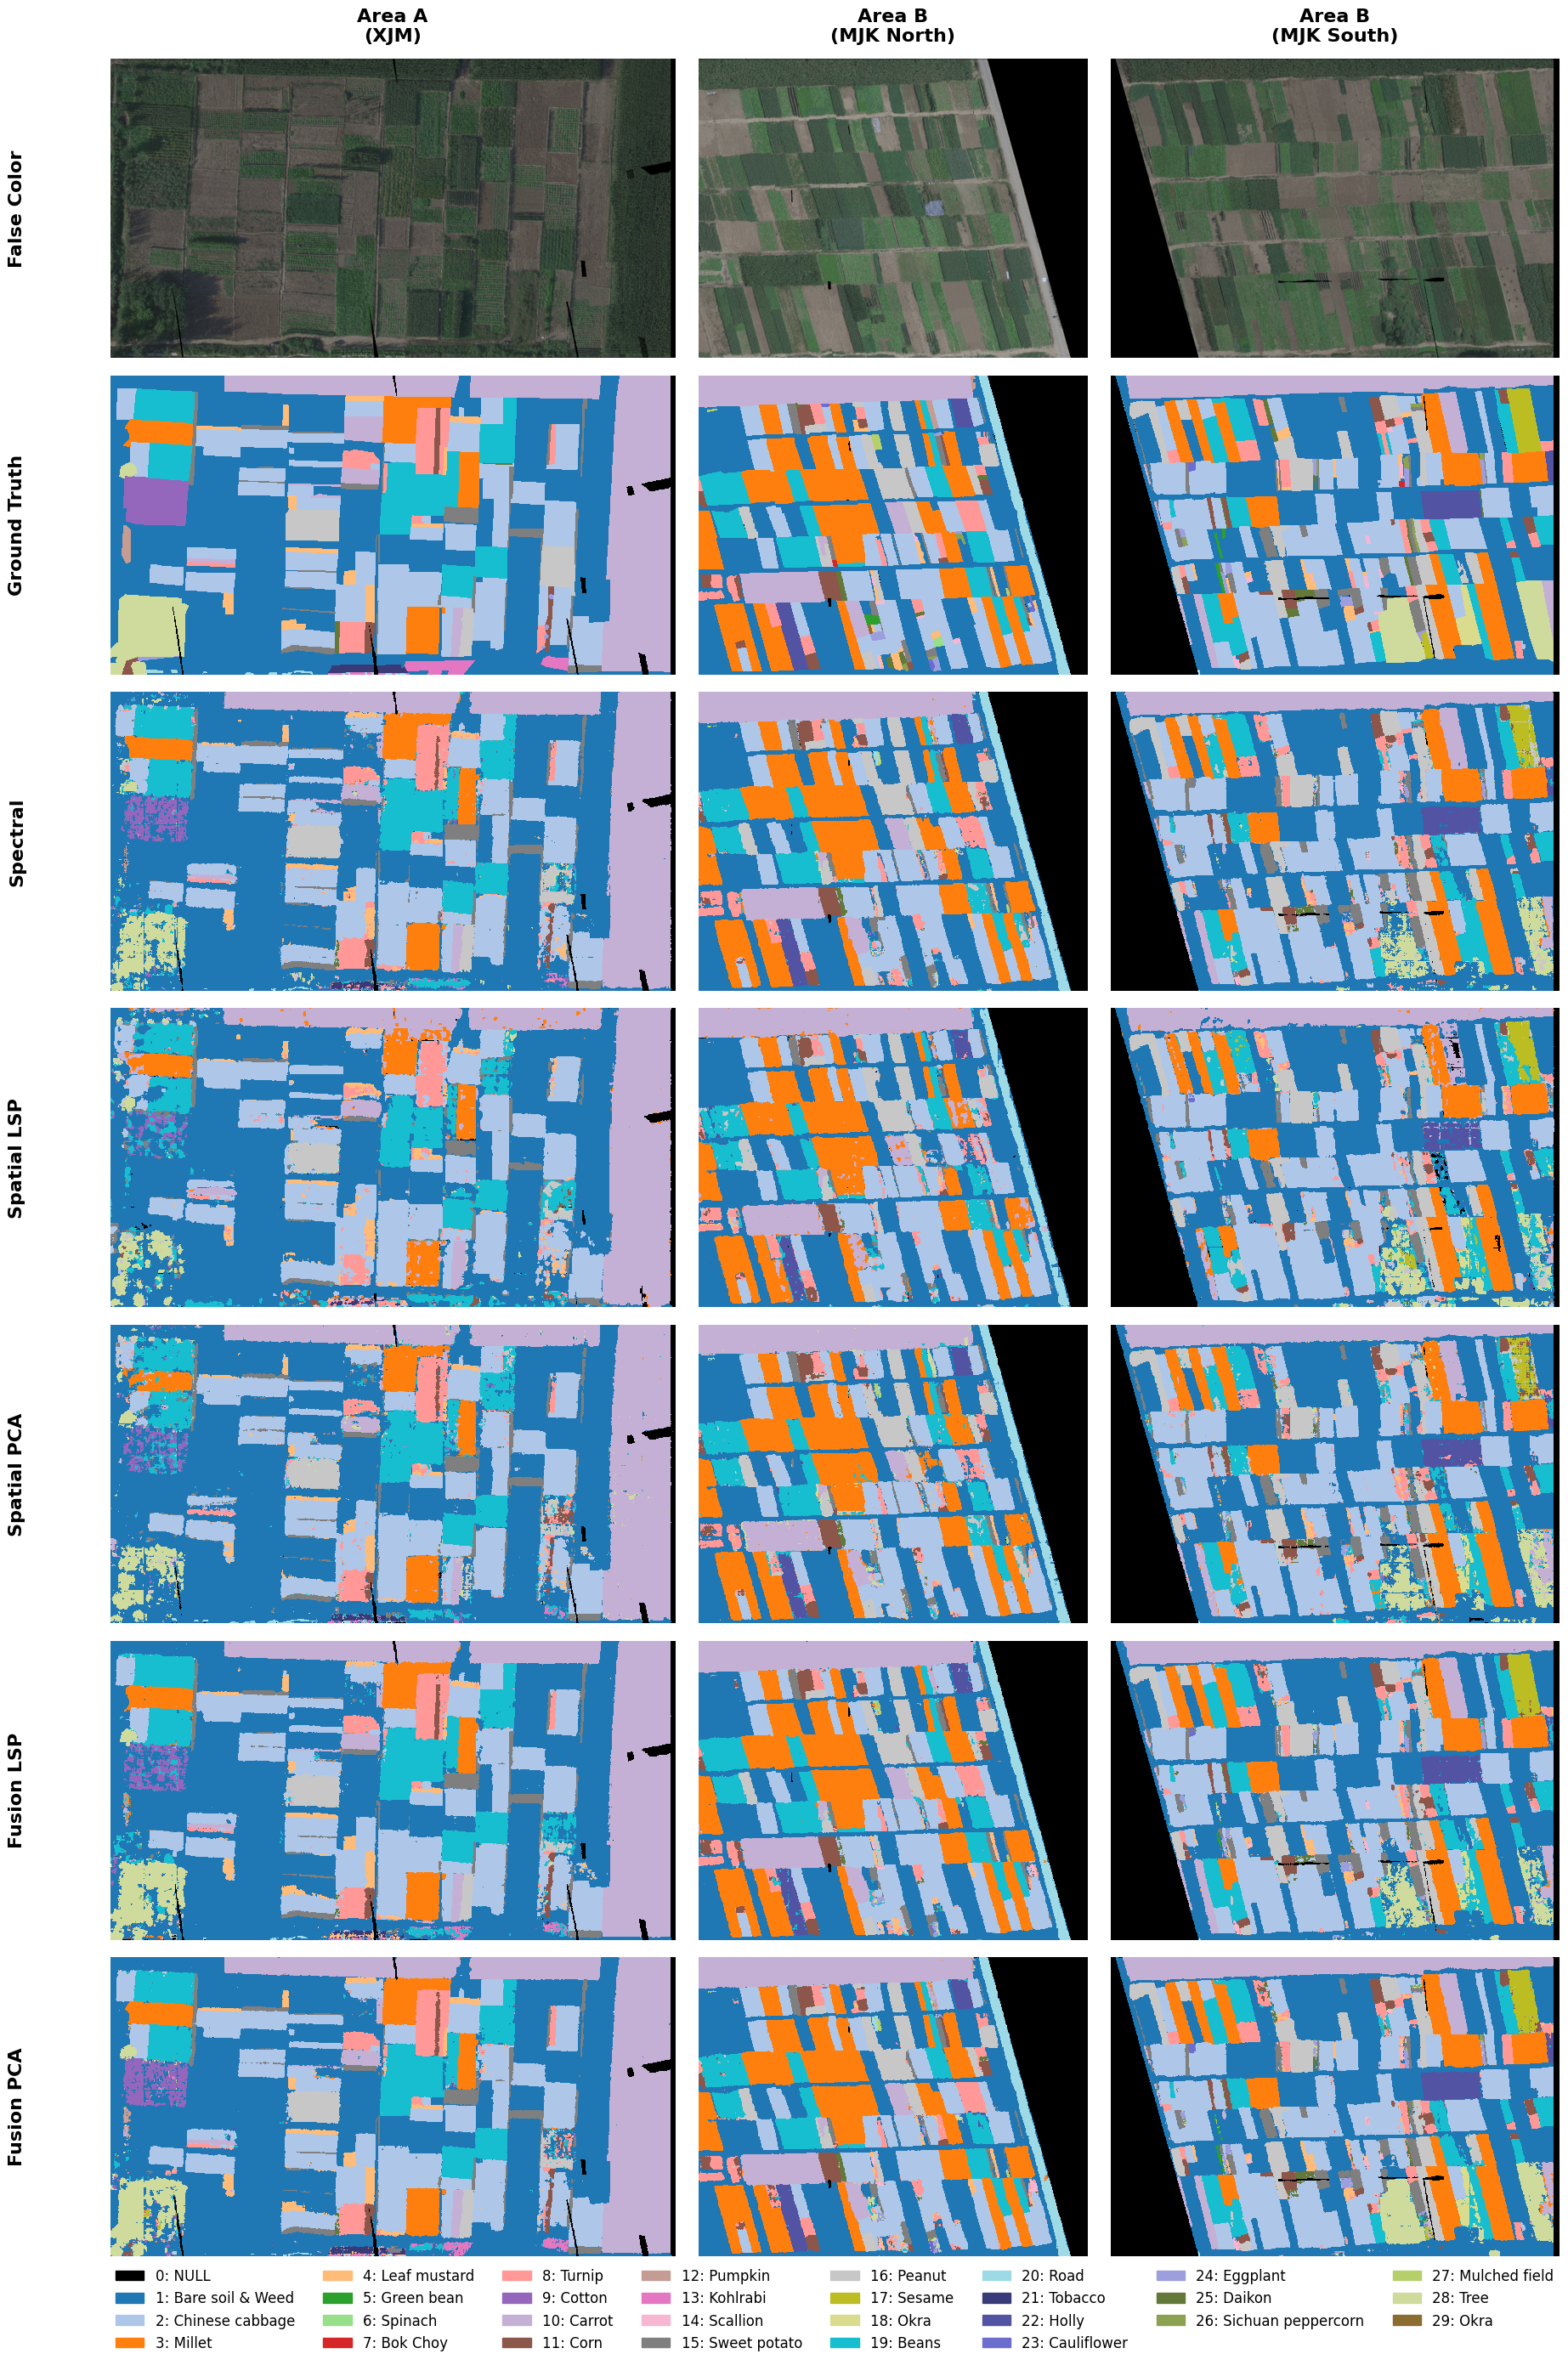

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import ListedColormap, BoundaryNorm
import numpy as np
import gc
import os
import glob
import tensorflow as tf
from tensorflow.keras.models import load_model

# =============================================================================
# 1. SETUP COLORMAP
# =============================================================================
def get_hsi_colormap():
    labels = [
        "NULL", "Bare soil & Weed", "Chinese cabbage", "Millet", "Leaf mustard",
        "Green bean", "Spinach", "Bok Choy", "Turnip", "Cotton", "Carrot",
        "Corn", "Pumpkin", "Kohlrabi", "Scallion", "Sweet potato", "Peanut",
        "Sesame", "Okra", "Beans", "Road", "Tobacco", "Holly", "Cauliflower",
        "Eggplant", "Daikon", "Sichuan peppercorn", "Mulched field", "Tree", "Okra"
    ]
    c1 = plt.get_cmap('tab20').colors
    c2 = plt.get_cmap('tab20b').colors
    c3 = plt.get_cmap('tab20c').colors
    colors = list(c1) + list(c2) + list(c3)
    colors = ['#000000'] + colors[:len(labels)-1]
    cmap = ListedColormap(colors)
    norm = BoundaryNorm(np.arange(len(labels) + 1) - 0.5, len(labels))
    return labels, cmap, norm, colors

# =============================================================================
# 2. DATA LOADER (RGB & GT)
# =============================================================================
def load_dataset_rgb_and_gt(base_dir, dataset_name):


    img, gt, _, _ = stack_image_patches(base_dir, data=dataset_name)
    if img is None or gt is None: return None, None

    try:
        if img.shape[-1] >= 84:
            r, g, b = img[:, :, 83], img[:, :, 50], img[:, :, 17]
            rgb = np.stack([r, g, b], axis=-1)
            if rgb.max() > 1: rgb = rgb / (rgb.max() + 1e-8)
            rgb = rgb ** 0.4
            rgb = np.clip(rgb, 0, 1)
        else:
            rgb = img[:, :, :3]
            if rgb.max() > 1: rgb = rgb / (rgb.max() + 1e-8)
    except:
        rgb = np.zeros((gt.shape[0], gt.shape[1], 3))

    if len(gt.shape) == 3: gt = gt[:, :, 0]
    del img
    gc.collect()
    return rgb, gt

# =============================================================================
# 3. HELPER: SELECT DATASET BY INTENT
# =============================================================================
def get_data_dir_by_intent(data_source_key, data_dirs):
    return data_dirs.get(data_source_key, data_dirs['raw'])

# =============================================================================
# 4. PREDICTION ENGINE
# =============================================================================
def load_and_predict_all_areas(data_dirs, patch_size=96):
    prediction_keys = ['spectral', 'spatial_lsp', 'spatial_pca', 'fusion_lsp', 'fusion_pca']
    datasets = ['XJM', 'MJK_N', 'MJK_S']
    all_predictions = {key: {} for key in prediction_keys}

    model_config = {
        'spectral': { 'path': "/content/ablation_checkpoints_pca/best_model_spectral_run_1.keras", 'inputs': {'spectral_input': 'raw'} },
        'spatial_lsp': { 'path': "/content/ablation_checkpoints/best_model_spatial_run_1.keras", 'inputs': {'spatial_input': 'lsp'} },
        'spatial_pca': { 'path': "/content/ablation_checkpoints_pca/best_model_spatial_run_1.keras", 'inputs': {'spatial_input': 'pca'} },
        'fusion_lsp': { 'path': "/content/ablation_checkpoints/best_model_fusion_run_1.keras", 'inputs': {'spectral_input': 'raw', 'spatial_input': 'lsp'} },
        'fusion_pca': { 'path': "/content/ablation_checkpoints_pca/best_model_fusion_run_1.keras", 'inputs': {'spectral_input': 'raw', 'spatial_input': 'pca'} }
    }

    for key in prediction_keys:
        print(f"\nProcessing Mode: {key.upper()}")
        config = model_config[key]
        path = config['path']
        if not os.path.exists(path):
            print(f"  ❌ Model not found: {path}")
            continue

        print(f"  Loading model: {os.path.basename(path)}")
        try:
            model = load_model(path, compile=False)
        except Exception as e:
            print(f"  Error loading model: {e}")
            continue

        input_configs = {}
        model_inputs = model.inputs
        if isinstance(model_inputs, list) and len(model_inputs) > 0:
            for input_tensor in model_inputs:
                name = input_tensor.name.split(':')[0]
                selected_dir = get_data_dir_by_intent(config['inputs'].get(name, 'raw'), data_dirs)
                input_configs[name] = selected_dir
        else:
             input_tensor = model_inputs
             name = input_tensor.name.split(':')[0]
             selected_dir = get_data_dir_by_intent(list(config['inputs'].values())[0], data_dirs)
             input_configs[name] = selected_dir

        for ds_name in datasets:
            print(f"    Predicting on {ds_name}...")
            feed_dict = {}
            valid_data = True

            for input_name, dir_path in input_configs.items():
                img_full, _, _, _ = stack_image_patches(dir_path, data=ds_name)
                if img_full is None:
                    print(f"      ❌ Missing data in {dir_path}")
                    valid_data = False
                    break
                h, w, c = img_full.shape
                pad_h = (patch_size - h % patch_size) % patch_size
                pad_w = (patch_size - w % patch_size) % patch_size
                img_padded = np.pad(img_full, ((0, pad_h), (0, pad_w), (0, 0)), mode='reflect')

                patches = []
                coords = []
                h_pad, w_pad, _ = img_padded.shape
                for r in range(0, h_pad, patch_size):
                    for c_idx in range(0, w_pad, patch_size):
                        patch = img_padded[r:r+patch_size, c_idx:c_idx+patch_size, :]
                        patches.append(patch)
                        coords.append((r, c_idx))

                feed_dict[input_name] = np.array(patches)
                del img_full, img_padded
                gc.collect()

            if not valid_data: continue

            try:
                preds_batch = model.predict(feed_dict, batch_size=4, verbose=0)
                preds_class = np.argmax(preds_batch, axis=-1)
                pred_map_padded = np.zeros((h_pad, w_pad), dtype=np.int32)
                for idx, (r, c_idx) in enumerate(coords):
                    pred_map_padded[r:r+patch_size, c_idx:c_idx+patch_size] = preds_class[idx]
                all_predictions[key][ds_name] = pred_map_padded[:h, :w]
                del feed_dict, preds_batch, pred_map_padded
                gc.collect()
            except Exception as e:
                print(f"      ❌ Prediction failed: {e}")
        del model
        gc.collect()

    return all_predictions

# =============================================================================
# 5. VISUALIZATION (TRANSPOSED LAYOUT)
# =============================================================================
def visualize_ablation_comparison(base_dir_rgb,
                                  predictions_dict,
                                  save_path="ablation_transposed.png"):
    datasets = ['XJM', 'MJK_N', 'MJK_S']
    col_titles = ['Area A\n(XJM)', 'Area B\n(MJK North)', 'Area B\n(MJK South)']

    # Rows: Methods
    row_labels = ["False Color", "Ground Truth", "Spectral", "Spatial LSP", "Spatial PCA", "Fusion LSP", "Fusion PCA"]
    pred_keys = ['spectral', 'spatial_lsp', 'spatial_pca', 'fusion_lsp', 'fusion_pca']

    labels, cmap, norm, color_list = get_hsi_colormap()

    print("\nGenering Transposed Plot...")

    # We need to organize data by COLUMNS (Areas) first to calculate width ratios
    # plot_data[col][row]
    plot_data_by_col = []
    width_ratios = []

    for i, ds_name in enumerate(datasets):
        rgb, gt = load_dataset_rgb_and_gt(base_dir_rgb, ds_name)

        col_maps = []
        col_maps.append(rgb) # Row 0
        col_maps.append(gt)  # Row 1
        for key in pred_keys:
            pmap = predictions_dict[key].get(ds_name, None)
            col_maps.append(pmap)

        # Rotation for XJM (Col 0)
        if i != 0:
            for idx, m in enumerate(col_maps):
                if m is not None: col_maps[idx] = np.rot90(m)

        plot_data_by_col.append(col_maps)

        # Calculate Aspect Ratio for width_ratios
        if rgb is not None:
            # Aspect Ratio = Width / Height
            # XJM (Rotated): Tall/Narrow -> Small Ratio
            # MJK (Normal): Wide/Short -> Large Ratio
            h, w = col_maps[0].shape[:2]
            width_ratios.append(w / h)
        else:
            width_ratios.append(1.0)

    # Figure Setup
    # 7 Rows, 3 Columns
    # Adjust Height ratios: All image rows should have same height weight (1)
    # Add legend row at bottom

    fig = plt.figure(figsize=(22, 35)) # Tall figure
    gs_heights = [1] * 7 + [0.25] # 7 Image rows + Legend

    gs = fig.add_gridspec(8, 3,
                          height_ratios=gs_heights,
                          width_ratios=width_ratios,
                          hspace=0.05, wspace=0.05)

    # Plot Loop
    # Iterate Cols (Areas) then Rows (Methods)
    for c_idx, col_maps in enumerate(plot_data_by_col):
        for r_idx, map_data in enumerate(col_maps):
            ax = fig.add_subplot(gs[r_idx, c_idx])

            if map_data is not None:
                if r_idx == 0: # RGB
                    ax.imshow(map_data)
                else: # Class Maps
                    ax.imshow(map_data, cmap=cmap, norm=norm, interpolation='nearest')

                # Column Titles (Top Row Only)
                if r_idx == 0:
                    ax.set_title(col_titles[c_idx], fontsize=16, fontweight='bold', pad=15)

                # Row Labels (Left Column Only)
                if c_idx == 0:
                    ax.text(-0.15, 0.5, row_labels[r_idx], transform=ax.transAxes,
                            fontsize=16, fontweight='bold', va='center', ha='right', rotation=90)
            else:
                ax.text(0.5, 0.5, "N/A", ha='center')

            ax.axis('off')

    # Legend (Row 8)
    ax_legend = fig.add_subplot(gs[7, :])
    ax_legend.axis('off')
    legend_patches = [mpatches.Patch(color=color_list[idx], label=f"{idx}: {label_text}") for idx, label_text in enumerate(labels)]
    ax_legend.legend(handles=legend_patches, loc='center', ncol=8, fontsize=12, frameon=False, bbox_to_anchor=(0.5, 0.5))

    print(f"Saving visualization to {save_path}...")
    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()

# --- MAIN EXECUTION ---
if __name__ == "__main__":
    DATA_DIRS = {
        'raw': "/content/dataset",
        'lsp': "/content/reverted_lsp",
        'pca': "/content/reverted"
    }

    print("🚀 Starting Automatic Prediction Pipeline...")
    all_preds = load_and_predict_all_areas(DATA_DIRS)

    if any([bool(d) for d in all_preds.values()]):
        visualize_ablation_comparison(DATA_DIRS['raw'], all_preds)
    else:
        print("❌ Visualization skipped due to missing predictions.")